# NSPPK Simplex Features: Dense Graphs and HIV

This notebook shows how NSPPK's active feature bins change as `radius`, `distance`, and `connector` vary. It first uses a small dense labeled graph so the neighborhood fragments are easy to inspect, then compares runtime and classification accuracy on a reproducible, class-balanced sample from the bundled HIV dataset.

The simplex comparison enables `use_simplex_features=True` with `simplex_feature_max_order=2`, which includes nodes, edges, and triangles. The HIV section uses one fixed train/test split so every configuration sees the same molecules. Increase `SAMPLE_PER_CLASS` or add repeated splits when you want a more stable accuracy estimate.

In [1]:
from pathlib import Path
import pickle
import sys
import time

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split

REPO_CANDIDATES = [Path.cwd().resolve(), Path.cwd().resolve().parent]
REPO_ROOT = next(path for path in REPO_CANDIDATES if (path / 'src').exists())
SRC_DIR = REPO_ROOT / 'src'
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from nsppk import NSPPK

RANDOM_STATE = 2026
NBITS = 12
SIMPLEX_MAX_ORDER = 2
HIV_PICKLE = REPO_ROOT / 'data' / 'HIV_networkx_graphs.pkl'

## 1. Dense labeled graph: count active feature bins

The graph below has six nodes and twelve edges (density 0.8). We compare three parameter sweeps:

- `radius = 0, 1, 2` with `distance=0`, `connector=0`
- `distance = 0, 1, 2, 3, 4` with `radius=1`, `connector=0`
- `connector = 0, 1, 2` with `radius=1`, `distance=4`

Each setting runs once with simplex features off and once with nodes, edges, and triangles enabled. `active_feature_bins` counts nonzero hashed columns (including the two reserved columns); hash collisions mean this is a bin count, not a count of raw fragment occurrences.

nodes=6, edges=12, density=0.80


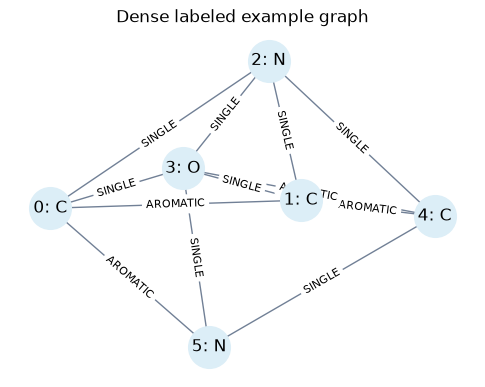

In [2]:
dense_graph = nx.Graph()
node_labels = {0: 'C', 1: 'C', 2: 'N', 3: 'O', 4: 'C', 5: 'N'}
dense_graph.add_nodes_from((node, {'label': label}) for node, label in node_labels.items())
dense_graph.add_edges_from([
    (0, 1), (0, 2), (0, 3), (0, 5),
    (1, 2), (1, 3), (1, 4),
    (2, 3), (2, 4),
    (3, 4), (3, 5), (4, 5),
])
for index, (u, v) in enumerate(dense_graph.edges()):
    dense_graph.edges[u, v]['label'] = 'AROMATIC' if index % 3 == 0 else 'SINGLE'

print(f'nodes={dense_graph.number_of_nodes()}, edges={dense_graph.number_of_edges()}, density={nx.density(dense_graph):.2f}')
pos = nx.spring_layout(dense_graph, seed=RANDOM_STATE)
fig, ax = plt.subplots(figsize=(6, 4.5))
nx.draw_networkx(
    dense_graph, pos=pos, ax=ax, with_labels=True,
    labels={node: f'{node}: {data["label"]}' for node, data in dense_graph.nodes(data=True)},
    node_color='#dceef7', edge_color='#718096', node_size=900,
)
edge_labels = {(u, v): data['label'] for u, v, data in dense_graph.edges(data=True)}
nx.draw_networkx_edge_labels(dense_graph, pos=pos, edge_labels=edge_labels, font_size=8, ax=ax)
ax.set_title('Dense labeled example graph')
ax.axis('off');


### What does an order-2 fragment look like?

Each triangle below is one order-2 simplex: three distinct vertices with all three edges present. The labels on its vertices and edges contribute to its fragment hash. The next section measures how these fragments change the active feature bins as the neighborhood settings grow.

order-2 simplex fragments in the dense graph: 9


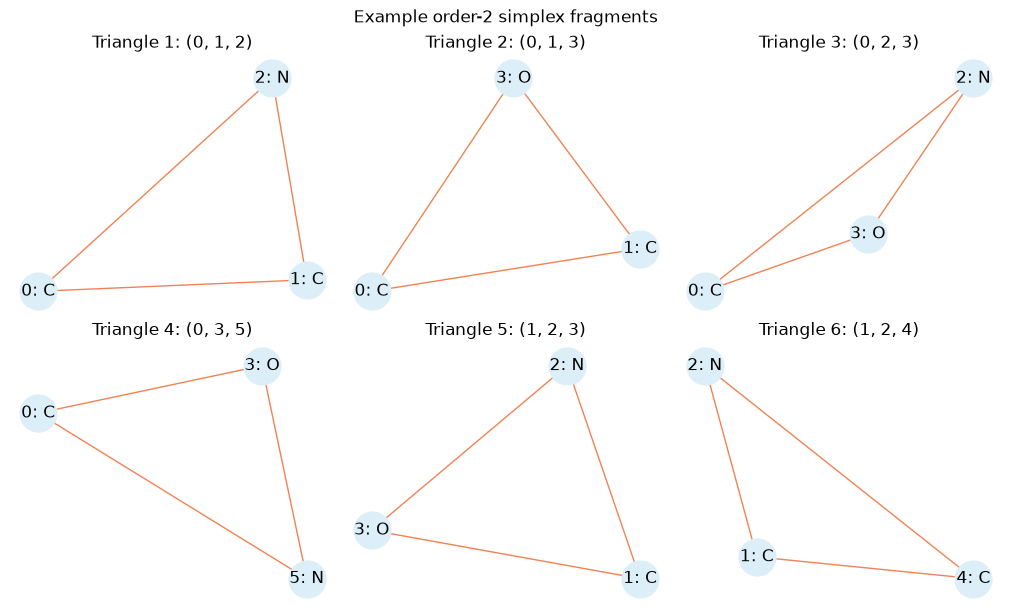

In [3]:
triangle_fragments = [
    tuple(clique)
    for clique in nx.enumerate_all_cliques(dense_graph)
    if len(clique) == 3
]
print(f'order-2 simplex fragments in the dense graph: {len(triangle_fragments)}')
shown_triangles = triangle_fragments[:min(6, len(triangle_fragments))]
fig, axes = plt.subplots(2, 3, figsize=(10, 6), constrained_layout=True)
for index, ax in enumerate(axes.flat):
    if index >= len(shown_triangles):
        ax.axis('off')
        continue
    triangle = shown_triangles[index]
    fragment = dense_graph.subgraph(triangle)
    nx.draw_networkx(
        fragment, pos=pos, ax=ax, with_labels=True,
        labels={node: f'{node}: {node_labels[node]}' for node in triangle},
        node_color='#dceef7', edge_color='#ef8354', node_size=700,
    )
    ax.set_title(f'Triangle {index + 1}: {triangle}')
    ax.axis('off')
fig.suptitle('Example order-2 simplex fragments');


In [4]:
sweep_configs = {
    'Radius': [(radius, 0, 0, radius) for radius in range(3)],
    'Distance': [(1, distance, 0, distance) for distance in range(5)],
    'Connector': [(1, 4, connector, connector) for connector in range(3)],
}

dense_rows = []
dense_vectors = {}
for sweep_name, configs in sweep_configs.items():
    for radius, distance, connector, sweep_value in configs:
        for use_simplex in (False, True):
            model = NSPPK(
                radius=radius, distance=distance, connector=connector,
                nbits=NBITS, dense=False, parallel=False,
                use_simplex_features=use_simplex,
                simplex_feature_max_order=SIMPLEX_MAX_ORDER,
            )
            started = time.perf_counter()
            vector = model.fit_transform([dense_graph]).toarray()[0]
            elapsed = time.perf_counter() - started
            dense_vectors[(sweep_name, sweep_value, use_simplex)] = vector
            dense_rows.append({
                'sweep': sweep_name,
                'setting': sweep_value,
                'radius': radius,
                'distance': distance,
                'connector': connector,
                'simplex_features': use_simplex,
                'active_feature_bins': int(np.count_nonzero(vector)),
                'structural_bins': int(np.count_nonzero(vector[2:])),
                'feature_mass': float(vector.sum()),
                'runtime_sec': elapsed,
            })

dense_results_df = pd.DataFrame(dense_rows)
display(dense_results_df.round(4))


,sweep,setting,radius,distance,connector,simplex_features,active_feature_bins,structural_bins,feature_mass,runtime_sec
0,Radius,0,0,0,0,False,5,3,36.0,0.0010
1,Radius,0,0,0,0,True,8,6,42.0,0.0009
2,Radius,1,1,0,0,False,20,18,54.0,0.0006
3,Radius,1,1,0,0,True,333,331,2672.0,0.0065
4,Radius,2,2,0,0,False,48,46,84.0,0.0005
5,Radius,2,2,0,0,True,373,371,13664.0,0.0231
6,Distance,0,1,0,0,False,20,18,54.0,0.0005
7,Distance,0,1,0,0,True,333,331,2672.0,0.0068
8,Distance,1,1,1,0,False,65,63,150.0,0.0007
9,Distance,1,1,1,0,True,711,709,13256.0,0.0213


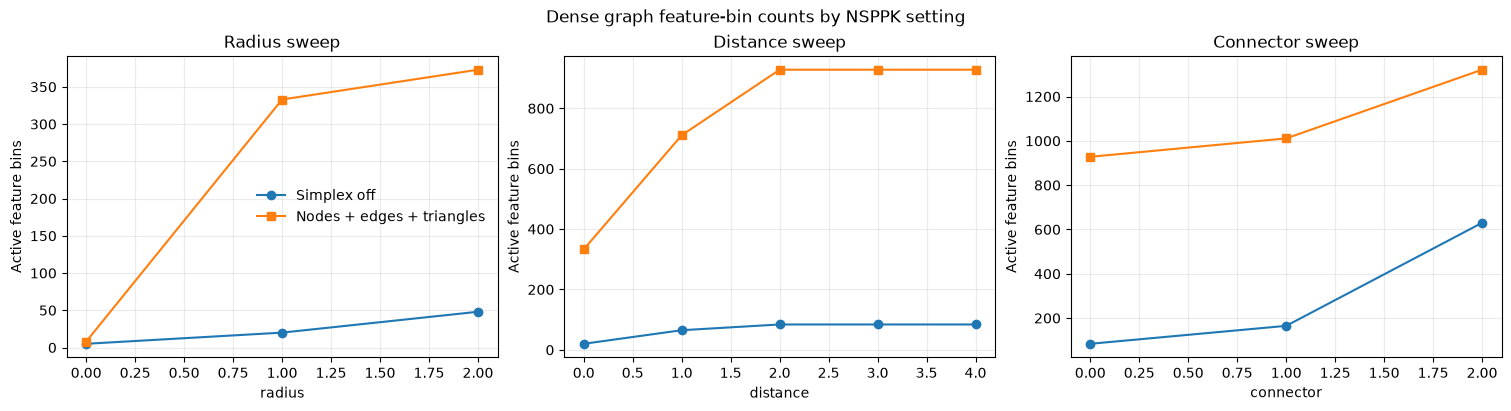

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4), constrained_layout=True)
for ax, (sweep_name, configs) in zip(axes, sweep_configs.items()):
    plot_df = dense_results_df[dense_results_df['sweep'] == sweep_name]
    for use_simplex, label, marker in ((False, 'Simplex off', 'o'), (True, 'Nodes + edges + triangles', 's')):
        series = plot_df[plot_df['simplex_features'] == use_simplex].sort_values('setting')
        ax.plot(series['setting'], series['active_feature_bins'], marker=marker, label=label)
    ax.set_title(f'{sweep_name} sweep')
    ax.set_xlabel(sweep_name.lower())
    ax.set_ylabel('Active feature bins')
    ax.grid(alpha=0.25)
axes[0].legend(frameon=False)
fig.suptitle('Dense graph feature-bin counts by NSPPK setting');


## 2. HIV graph sample and fixed split

The repository includes NetworkX graphs and activity labels in `data/HIV_networkx_graphs.pkl`, so this section does not download data or rebuild molecules. The positive class is rare in the full dataset; for a quick, interpretable comparison, the code selects the same number of active and inactive molecules and uses a stratified 75/25 split. The sample size can be increased below.

In [6]:
SAMPLE_PER_CLASS = 100  # 200 molecules total by default
with HIV_PICKLE.open('rb') as handle:
    hiv_data = pickle.load(handle)
hiv_graphs_all = hiv_data['graphs']
hiv_labels_all = np.asarray(hiv_data['labels'], dtype=int)

rng = np.random.default_rng(RANDOM_STATE)
class_indices = [np.flatnonzero(hiv_labels_all == label) for label in (0, 1)]
if any(len(indices) < SAMPLE_PER_CLASS for indices in class_indices):
    raise ValueError('SAMPLE_PER_CLASS exceeds the available HIV examples in a class.')
sampled_indices = np.concatenate([
    rng.choice(indices, size=SAMPLE_PER_CLASS, replace=False)
    for indices in class_indices
])
rng.shuffle(sampled_indices)
hiv_graphs = [hiv_graphs_all[index] for index in sampled_indices]
hiv_labels = hiv_labels_all[sampled_indices]
train_indices, test_indices = train_test_split(
    np.arange(len(hiv_graphs)), test_size=0.25,
    random_state=RANDOM_STATE, stratify=hiv_labels,
)
print(f'Full bundled dataset: {len(hiv_graphs_all):,} graphs; class counts={np.bincount(hiv_labels_all).tolist()}')
print(f'Benchmark sample: {len(hiv_graphs):,} balanced graphs; train={len(train_indices)}, test={len(test_indices)}')
print(f'Train class counts={np.bincount(hiv_labels[train_indices]).tolist()}, test class counts={np.bincount(hiv_labels[test_indices]).tolist()}')


Full bundled dataset: 41,120 graphs; class counts=[39677, 1443]
Benchmark sample: 200 balanced graphs; train=150, test=50
Train class counts=[75, 75], test class counts=[25, 25]


## 3. HIV runtime and classification accuracy

Every unique `(radius, distance, connector)` combination from the three sweeps is evaluated with simplex features off and on. Duplicate parameter combinations across sweeps are computed once and labeled with both sweep names. NSPPK feature generation is timed separately from logistic-regression fitting and prediction. Accuracy and balanced accuracy are measured on the same held-out test molecules for every run.

In [7]:
config_groups = {}
for sweep_name, configs in sweep_configs.items():
    for radius, distance, connector, sweep_value in configs:
        key = (radius, distance, connector)
        config_groups.setdefault(key, []).append((sweep_name, sweep_value))

hiv_rows = []
for (radius, distance, connector), group_values in config_groups.items():
    sweep_labels = ', '.join(f'{name}={value}' for name, value in group_values)
    for use_simplex in (False, True):
        vectorizer = NSPPK(
            radius=radius, distance=distance, connector=connector,
            nbits=NBITS, dense=False, parallel=False,
            use_simplex_features=use_simplex,
            simplex_feature_max_order=SIMPLEX_MAX_ORDER,
        )
        feature_started = time.perf_counter()
        feature_matrix = vectorizer.fit_transform(hiv_graphs)
        feature_seconds = time.perf_counter() - feature_started

        classifier = LogisticRegression(
            solver='liblinear', max_iter=300, class_weight='balanced',
            random_state=RANDOM_STATE,
        )
        fit_started = time.perf_counter()
        classifier.fit(feature_matrix[train_indices], hiv_labels[train_indices])
        classifier_fit_seconds = time.perf_counter() - fit_started

        predict_started = time.perf_counter()
        predictions = classifier.predict(feature_matrix[test_indices])
        predict_seconds = time.perf_counter() - predict_started
        accuracy = accuracy_score(hiv_labels[test_indices], predictions)
        balanced_accuracy = balanced_accuracy_score(hiv_labels[test_indices], predictions)

        hiv_rows.append({
            'sweeps': sweep_labels,
            'radius': radius,
            'distance': distance,
            'connector': connector,
            'simplex_features': use_simplex,
            'max_order': SIMPLEX_MAX_ORDER if use_simplex else None,
            'feature_runtime_sec': feature_seconds,
            'classifier_fit_sec': classifier_fit_seconds,
            'predict_sec': predict_seconds,
            'end_to_end_sec': feature_seconds + classifier_fit_seconds + predict_seconds,
            'accuracy': accuracy,
            'balanced_accuracy': balanced_accuracy,
            'feature_nnz': int(feature_matrix.nnz),
        })
        print(
            f'{sweep_labels:30s} simplex={use_simplex!s:5s} '
            f'features={feature_seconds:7.2f}s accuracy={accuracy:.3f} '
            f'balanced_accuracy={balanced_accuracy:.3f}'
        )

hiv_results_df = pd.DataFrame(hiv_rows)
display(hiv_results_df.round(4))


Radius=0                       simplex=False features=   0.14s accuracy=0.520 balanced_accuracy=0.520


Radius=0                       simplex=True  features=   0.24s accuracy=0.520 balanced_accuracy=0.520
Radius=1, Distance=0           simplex=False features=   0.18s accuracy=0.600 balanced_accuracy=0.600


Radius=1, Distance=0           simplex=True  features=   0.96s accuracy=0.660 balanced_accuracy=0.660


Radius=2                       simplex=False features=   0.23s accuracy=0.560 balanced_accuracy=0.560


Radius=2                       simplex=True  features=   4.06s accuracy=0.620 balanced_accuracy=0.620


Distance=1                     simplex=False features=   0.26s accuracy=0.540 balanced_accuracy=0.540


... (8 outputs left out)

Connector=1                    simplex=True  features=  10.80s accuracy=0.720 balanced_accuracy=0.720


Connector=2                    simplex=False features=   3.20s accuracy=0.640 balanced_accuracy=0.640


Connector=2                    simplex=True  features=  54.60s accuracy=0.660 balanced_accuracy=0.660


,sweeps,radius,distance,connector,simplex_features,max_order,feature_runtime_sec,classifier_fit_sec,predict_sec,end_to_end_sec,accuracy,balanced_accuracy,feature_nnz
0,Radius=0,0,0,0,False,NaN,0.1359,0.0023,0.0002,0.1384,0.52,0.52,2210
1,Radius=0,0,0,0,True,2.0,0.2405,0.0021,0.0001,0.2426,0.52,0.52,4017
2,"Radius=1, Distance=0",1,0,0,False,NaN,0.1775,0.0022,0.0001,0.1799,0.60,0.60,14678
3,"Radius=1, Distance=0",1,0,0,True,2.0,0.9568,0.0096,0.0002,0.9666,0.66,0.66,48068
4,Radius=2,2,0,0,False,NaN,0.2295,0.0030,0.0001,0.2326,0.56,0.56,35598
5,Radius=2,2,0,0,True,2.0,4.0581,0.0194,0.0004,4.0779,0.62,0.62,124848
6,Distance=1,1,1,0,False,NaN,0.2556,0.0040,0.0002,0.2598,0.54,0.54,42170
7,Distance=1,1,1,0,True,2.0,2.6462,0.0202,0.0003,2.6667,0.62,0.62,120451
8,Distance=2,1,2,0,False,NaN,0.4133,0.0071,0.0003,0.4207,0.58,0.58,76107
9,Distance=2,1,2,0,True,2.0,3.1265,0.0254,0.0003,3.1522,0.62,0.62,193292


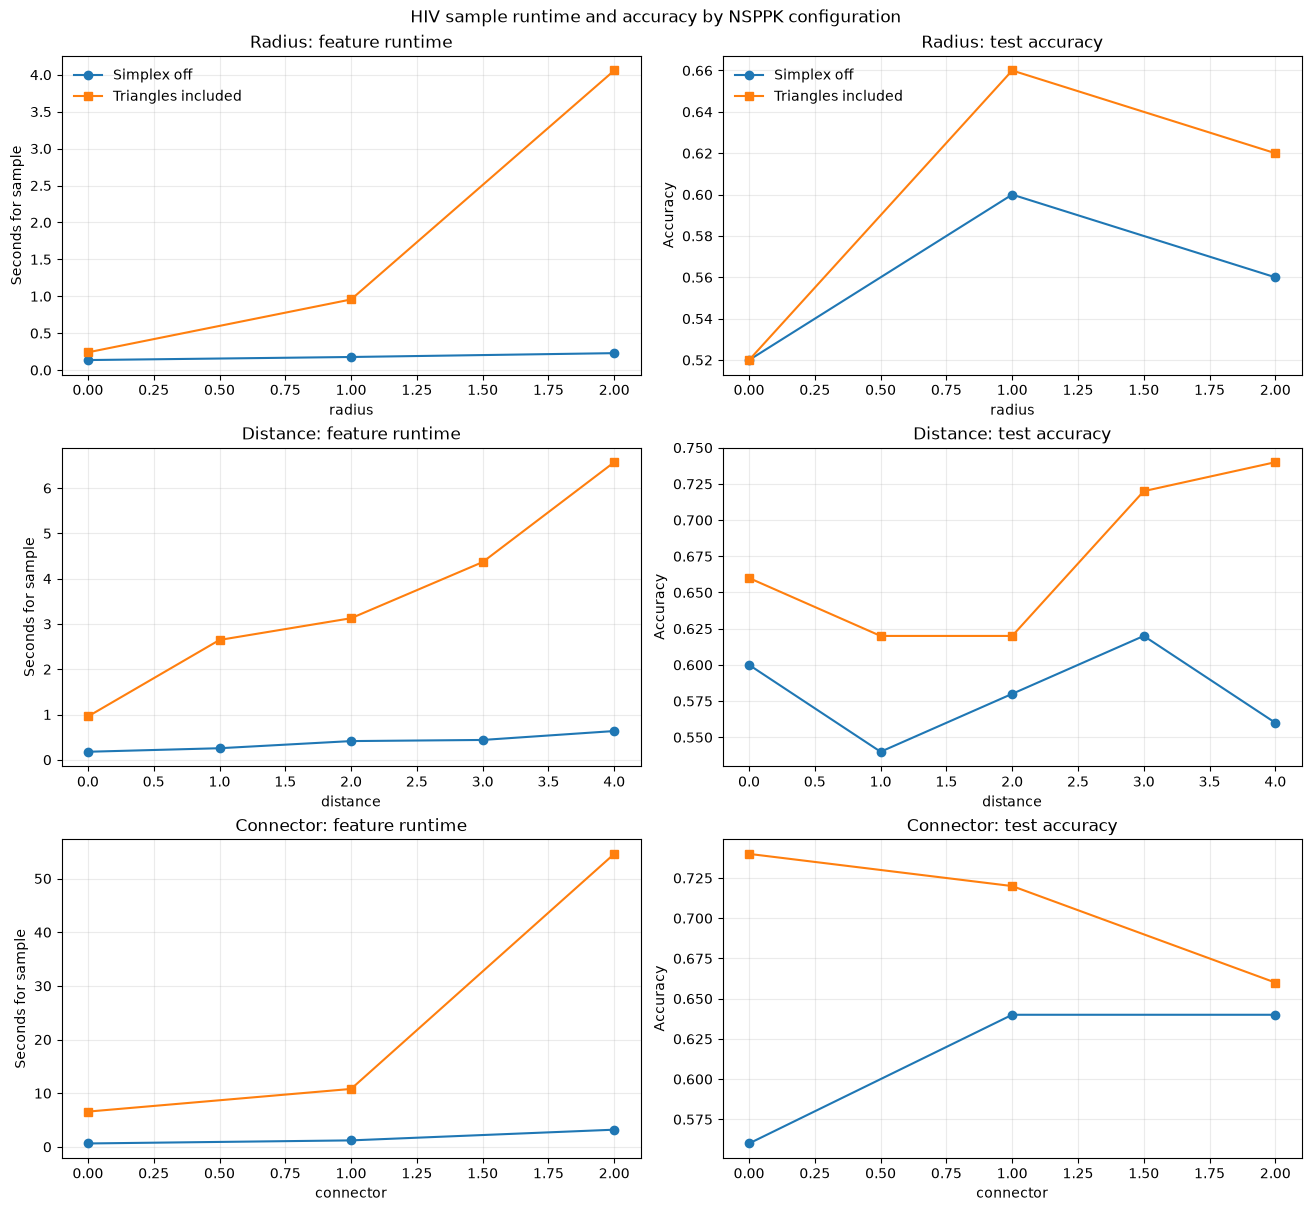

In [8]:
fig, axes = plt.subplots(3, 2, figsize=(13, 12), constrained_layout=True)
for row, sweep_name in enumerate(('Radius', 'Distance', 'Connector')):
    sweep_df = hiv_results_df[hiv_results_df['sweeps'].str.contains(rf'{sweep_name}=')].copy()
    value_column = sweep_name.lower()
    for use_simplex, label, marker in ((False, 'Simplex off', 'o'), (True, 'Triangles included', 's')):
        series = sweep_df[sweep_df['simplex_features'] == use_simplex].sort_values(value_column)
        axes[row, 0].plot(series[value_column], series['feature_runtime_sec'], marker=marker, label=label)
        axes[row, 1].plot(series[value_column], series['accuracy'], marker=marker, label=label)
    axes[row, 0].set_title(f'{sweep_name}: feature runtime')
    axes[row, 0].set_ylabel('Seconds for sample')
    axes[row, 1].set_title(f'{sweep_name}: test accuracy')
    axes[row, 1].set_ylabel('Accuracy')
    for ax in axes[row]:
        ax.set_xlabel(sweep_name.lower())
        ax.grid(alpha=0.25)
axes[0, 0].legend(frameon=False)
axes[0, 1].legend(frameon=False)
fig.suptitle('HIV sample runtime and accuracy by NSPPK configuration');


## Interpretation

- `active_feature_bins` and `feature_nnz` count occupied hashed columns. They are not exact counts of unique simplex fragments because different signatures can collide into the same bin.
- Simplex order 2 adds triangle fragments; high-degree neighborhoods can therefore cost more than baseline hashing. The per-graph cache reuses fragments for repeated induced neighborhoods and path regions within each transform.
- HIV results here are a quick balanced-sample comparison from one split. Increase `SAMPLE_PER_CLASS` and repeat stratified splits before using the accuracy values as model-selection evidence. Compare balanced accuracy alongside accuracy because the full HIV labels are strongly imbalanced.